# Objective 2 — Typed N-ary multi-contract graph representation
**Goal (from the project plan):** a representation that is not limited to two contracts. Every contract an exploit touches is
connected in one graph, and each cross-contract link is *typed* by why the contracts are linked.

**Representation** (one graph per exploit):
- **Nodes**: basic blocks visited by feasible execution traces, starting from the attacker's exploit functions. Features: opcode
  histogram, block size, contract role (attacker / protocol / shared infrastructure), call depth.
- **N-ary chaining**: at every CALL / STATICCALL / DELEGATECALL / CALLCODE the callee is resolved (pushed address constant first,
  otherwise the 4-byte selector) and its trace is stitched in **recursively** (depth ≤ 3; callbacks into the attacker allowed).
- **7 edge types**: `cfg`, `call_write` (callee writes storage), `call_read` (view / STATICCALL), `delegate`
  (DELEGATECALL / CALLCODE), `return`, `revert_guard` (caller checks the call result and reverts), `storage_dep`
  (SSTORE → later SLOAD of the same slot).

**Ablation** (same R-GCN, same 704 exploits, same incident-level 5-fold × 3-seed CV as Objective 1):
- **Contracts per graph:** pairwise (DeFiTail view: attacker + 1 protocol contract), N-ary protocol (attacker + all protocol
  contracts), N-ary all (adds shared tokens, lenders and routers).
- **Edge types:** typed (7 types) vs untyped (one type).
- **Control:** pairwise trained on one pair per exploit, so it has the same number of training graphs as N-ary.

Uses Objective 1's data (`data/raw`, `data/processed`). Outputs: `data/processed/o2_graphs/`, `results_o2/`.
Every expensive step is cached: building graphs ~20 min sequentially (once), training ~4.5 h (per-fold checkpoints).

In [1]:
import json, math, re, time
from pathlib import Path
from collections import defaultdict
import numpy as np, pandas as pd, torch, torch.nn as nn
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader
from torch_geometric.nn import RGCNConv, global_mean_pool, global_max_pool
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
import matplotlib.pyplot as plt
from IPython.display import Image, display

ROOT = Path.cwd()                          # run from the objective1 folder
DATA = ROOT / "data"
GDIR = DATA / "processed" / "o2_graphs"
RES = ROOT / "results_o2"
GDIR.mkdir(parents=True, exist_ok=True); RES.mkdir(exist_ok=True)
TASKS, BUCKETS = ["access_control", "flash_loan"], ["2", "3-5", "6-10", "11+"]
torch.set_num_threads(8)

## 1. EVM helpers (same disassembler and symbolic-stack conventions as Objective 1)

In [2]:
M = (1 << 256) - 1
NAMES, EFFECT = {}, {}   # opcode -> name ; opcode -> (pops, pushes)
def _op(code, name, pops, pushes): NAMES[code] = name; EFFECT[code] = (pops, pushes)
for c, n, p, q in [
    (0x00, "STOP", 0, 0), (0x01, "ADD", 2, 1), (0x02, "MUL", 2, 1), (0x03, "SUB", 2, 1), (0x04, "DIV", 2, 1),
    (0x05, "SDIV", 2, 1), (0x06, "MOD", 2, 1), (0x07, "SMOD", 2, 1), (0x08, "ADDMOD", 3, 1), (0x09, "MULMOD", 3, 1),
    (0x0a, "EXP", 2, 1), (0x0b, "SIGNEXTEND", 2, 1), (0x10, "LT", 2, 1), (0x11, "GT", 2, 1), (0x12, "SLT", 2, 1),
    (0x13, "SGT", 2, 1), (0x14, "EQ", 2, 1), (0x15, "ISZERO", 1, 1), (0x16, "AND", 2, 1), (0x17, "OR", 2, 1),
    (0x18, "XOR", 2, 1), (0x19, "NOT", 1, 1), (0x1a, "BYTE", 2, 1), (0x1b, "SHL", 2, 1), (0x1c, "SHR", 2, 1),
    (0x1d, "SAR", 2, 1), (0x20, "KECCAK256", 2, 1), (0x30, "ADDRESS", 0, 1), (0x31, "BALANCE", 1, 1),
    (0x32, "ORIGIN", 0, 1), (0x33, "CALLER", 0, 1), (0x34, "CALLVALUE", 0, 1), (0x35, "CALLDATALOAD", 1, 1),
    (0x36, "CALLDATASIZE", 0, 1), (0x37, "CALLDATACOPY", 3, 0), (0x38, "CODESIZE", 0, 1), (0x39, "CODECOPY", 3, 0),
    (0x3a, "GASPRICE", 0, 1), (0x3b, "EXTCODESIZE", 1, 1), (0x3c, "EXTCODECOPY", 4, 0),
    (0x3d, "RETURNDATASIZE", 0, 1), (0x3e, "RETURNDATACOPY", 3, 0), (0x3f, "EXTCODEHASH", 1, 1),
    (0x40, "BLOCKHASH", 1, 1), (0x41, "COINBASE", 0, 1), (0x42, "TIMESTAMP", 0, 1), (0x43, "NUMBER", 0, 1),
    (0x44, "PREVRANDAO", 0, 1), (0x45, "GASLIMIT", 0, 1), (0x46, "CHAINID", 0, 1), (0x47, "SELFBALANCE", 0, 1),
    (0x48, "BASEFEE", 0, 1), (0x49, "BLOBHASH", 1, 1), (0x4a, "BLOBBASEFEE", 0, 1), (0x50, "POP", 1, 0),
    (0x51, "MLOAD", 1, 1), (0x52, "MSTORE", 2, 0), (0x53, "MSTORE8", 2, 0), (0x54, "SLOAD", 1, 1),
    (0x55, "SSTORE", 2, 0), (0x56, "JUMP", 1, 0), (0x57, "JUMPI", 2, 0), (0x58, "PC", 0, 1), (0x59, "MSIZE", 0, 1),
    (0x5a, "GAS", 0, 1), (0x5b, "JUMPDEST", 0, 0), (0x5c, "TLOAD", 1, 1), (0x5d, "TSTORE", 2, 0),
    (0x5e, "MCOPY", 3, 0), (0x5f, "PUSH0", 0, 1), (0xf0, "CREATE", 3, 1), (0xf1, "CALL", 7, 1),
    (0xf2, "CALLCODE", 7, 1), (0xf3, "RETURN", 2, 0), (0xf4, "DELEGATECALL", 6, 1), (0xf5, "CREATE2", 4, 1),
    (0xfa, "STATICCALL", 6, 1), (0xfd, "REVERT", 2, 0), (0xfe, "INVALID", 0, 0), (0xff, "SELFDESTRUCT", 1, 0)]:
    _op(c, n, p, q)
for i in range(1, 33): _op(0x5f + i, f"PUSH{i}", 0, 1)
for i in range(1, 17): NAMES[0x7f + i] = f"DUP{i}"; NAMES[0x8f + i] = f"SWAP{i}"
for i in range(5): _op(0xa0 + i, f"LOG{i}", 2 + i, 0)

SUCCESS = {0x00, 0xf3, 0xff}          # STOP, RETURN, SELFDESTRUCT
FAIL = {0xfd, 0xfe}                   # REVERT, INVALID
CALLS = {0xf1, 0xf2, 0xf4, 0xfa}      # CALL, CALLCODE, DELEGATECALL, STATICCALL
CALLDATASIZE = 4 + 32 * 16            # assume well-formed calldata so ABI length checks pass


def disassemble(hexcode):
    b = bytes.fromhex(hexcode[2:] if hexcode.startswith("0x") else hexcode)
    ins, i = [], 0
    while i < len(b):
        op = b[i]
        n = op - 0x5f if 0x60 <= op <= 0x7f else 0
        val = int.from_bytes(b[i + 1:i + 1 + n], "big") if n else (0 if op == 0x5f else None)
        ins.append((i, op, val))
        i += 1 + n
    return ins


class Contract:
    def __init__(self, hexcode, name=""):
        self.name = name
        self.ins = disassemble(hexcode)
        self.at = {pc: k for k, (pc, _, _) in enumerate(self.ins)}            # pc -> instruction index
        self.jumpdests = {pc for pc, op, _ in self.ins if op == 0x5b}
        self.selectors = self._dispatcher()

    def _dispatcher(self):
        """Selectors from the `PUSH4 sel ... EQ ... PUSHn dest JUMPI` dispatcher pattern."""
        sels, ins = set(), self.ins
        for k, (pc, op, v) in enumerate(ins):
            if op == 0x63 and v:
                window = [o for _, o, _ in ins[k + 1:k + 5]]
                if 0x14 in window and 0x57 in window:
                    sels.add(v)
        return sels


def _alu(op, a):
    """Constant-fold a few ops used by dispatchers / jump-target arithmetic; None = unknown."""
    if any(x is None for x in a):
        return None
    try:
        if op == 0x01: return (a[0] + a[1]) & M
        if op == 0x02: return (a[0] * a[1]) & M
        if op == 0x03: return (a[0] - a[1]) & M
        if op == 0x04: return a[0] // a[1] if a[1] else 0
        if op == 0x10: return int(a[0] < a[1])
        if op == 0x11: return int(a[0] > a[1])
        if op == 0x14: return int(a[0] == a[1])
        if op == 0x15: return int(a[0] == 0)
        if op == 0x16: return a[0] & a[1]
        if op == 0x17: return a[0] | a[1]
        if op == 0x18: return a[0] ^ a[1]
        if op == 0x19: return (~a[0]) & M
        if op == 0x1b: return (a[1] << a[0]) & M if a[0] < 256 else 0
        if op == 0x1c: return a[1] >> a[0] if a[0] < 256 else 0
    except Exception:
        return None
    return None

## 2. Typed N-ary graph builder
`function_trace` = Objective 1's feasible-path search, recording program counters, storage slots and revert-guard branches.
`GraphBuilder` stitches calls recursively among an *allowed* set of contracts; `build_variants` makes the three variants.

In [3]:
# ---------------- edge types ----------------
EDGE_TYPES = ["cfg", "call_write", "call_read", "delegate", "return", "revert_guard", "storage_dep"]
ET = {n: i for i, n in enumerate(EDGE_TYPES)}
ROLES = ["attacker", "protocol", "shared"]
MAX_DEPTH = 3
BUDGET = 60000                     # instructions walked per graph (bounds graph size)
TERMINATORS = {0x00, 0x56, 0x57, 0xf3, 0xfd, 0xfe, 0xff}
SEM_OPS = sorted({n for c, n in NAMES.items() if not n.startswith(("PUSH", "DUP", "SWAP")) and n not in ("POP", "JUMPDEST")})
SEM_IDX = {n: i for i, n in enumerate(SEM_OPS)}
N_FEAT = len(SEM_OPS) + 1 + len(ROLES) + (MAX_DEPTH + 1)


class TContract(Contract):
    """Contract + basic-block map + 'does this successor revert quickly?' test for revert-guard edges."""
    def __init__(self, hexcode, name="", address="", role="protocol"):
        super().__init__(hexcode, name)
        self.address, self.role = address, role
        self.block_of, start = {}, 0
        for k, (pc, op, v) in enumerate(self.ins):
            if op == 0x5b: start = pc                                # JUMPDEST always starts a block
            self.block_of[pc] = start
            if op in TERMINATORS and k + 1 < len(self.ins): start = self.ins[k + 1][0]
        self._rq = {}

    def reverts_quickly(self, k, hops=1):
        if (k, hops) in self._rq: return self._rq[(k, hops)]
        res, last_push = False, None
        for j in range(k, min(k + 40, len(self.ins))):
            pc, op, v = self.ins[j]
            if op in (0xfd, 0xfe): res = True; break
            if op in (0x00, 0xf3, 0xff, 0x57): break
            if op == 0x56:
                if hops and last_push in self.at: res = self.reverts_quickly(self.at[last_push], hops - 1)
                break
            last_push = v if 0x60 <= op <= 0x7f else last_push
        self._rq[(k, hops)] = res
        return res

    def block_features(self, block_pc):
        counts, n, k = np.zeros(len(SEM_OPS)), 0, self.at[block_pc]
        while k < len(self.ins):
            pc, op, v = self.ins[k]
            if self.block_of.get(pc) != block_pc: break
            name = NAMES.get(op)
            if name in SEM_IDX: counts[SEM_IDX[name]] += 1
            n += 1; k += 1
            if op in TERMINATORS: break
        return counts / max(n, 1), n


def function_trace(c, selector, max_len=40000, max_steps=2000000, max_visits=32, unroll=4):
    """First feasible successful execution of `selector` (same search as Objective 1), recorded with program
    counters. Entries: (pc, op, value, aux); aux = storage slot for SLOAD/SSTORE, True for revert-guarding JUMPIs."""
    steps = 0
    todo = [(0, (), (), {}, None)]
    while todo and steps < max_steps:
        k, st, path, visits, last = todo.pop()
        st, path, visits = list(st), list(path), dict(visits)
        while True:
            steps += 1
            if k >= len(c.ins) or len(path) > max_len or steps > max_steps: break
            pc, op, v = c.ins[k]
            if op == 0x5b:
                visits[pc] = visits.get(pc, 0) + 1; last = pc
                if visits[pc] > max_visits: break
            if op in SUCCESS:
                path.append((pc, op, None, None)); return path
            if op in FAIL or op not in EFFECT and not (0x80 <= op <= 0x9f): break
            if 0x80 <= op <= 0x8f:
                n = op - 0x7f
                if len(st) < n: break
                st.append(st[-n]); path.append((pc, op, None, None)); k += 1; continue
            if 0x90 <= op <= 0x9f:
                n = op - 0x8f
                if len(st) < n + 1: break
                st[-1], st[-1 - n] = st[-1 - n], st[-1]; path.append((pc, op, None, None)); k += 1; continue
            pops, pushes = EFFECT[op]
            if len(st) < pops: break
            args = [st.pop() for _ in range(pops)]
            if op == 0x56:
                t = args[0]
                if t is None or t not in c.jumpdests: break
                path.append((pc, op, None, None)); k = c.at[t]; continue
            if op == 0x57:
                t, cond = args
                if t is None or t not in c.jumpdests: break
                if cond is not None and last is not None and visits.get(last, 0) > unroll: cond = None
                if cond is None:
                    alt_taken = c.reverts_quickly(k + 1)          # if we take the jump, the fall-through is the alternative
                    todo.append((c.at[t], tuple(st), tuple(path + [(pc, op, None, alt_taken)]), dict(visits), last))
                    path.append((pc, op, None, c.reverts_quickly(c.at[t]))); k += 1; continue
                nxt = c.at[t] if cond else k + 1
                alt = k + 1 if cond else c.at[t]
                path.append((pc, op, None, c.reverts_quickly(alt))); k = nxt; continue
            aux = args[0] if op in (0x54, 0x55) else None
            path.append((pc, op, v, aux))
            if 0x60 <= op <= 0x7f or op == 0x5f: st.append(v)
            elif op == 0x35: st.append((selector << 224) if args[0] == 0 else None)
            elif op == 0x36: st.append(CALLDATASIZE)
            elif pushes: st.append(_alu(op, args))
            if len(st) > 1024: break
            k += 1
    return None


class GraphBuilder:
    """Builds one graph over a set of allowed contracts, starting from the attacker's exploit functions."""
    def __init__(self, attacker, roots, allowed, trace_cache):
        self.att = attacker                    # list of TContract (attacker side)
        self.allowed = allowed                 # list of TContract that calls may be stitched into
        self.by_addr = {c.address: c for c in allowed if c.address}
        self.roots, self.tc = roots, trace_cache
        self.nodes, self.order, self.depth = {}, [], {}
        self.edges, self.storage = set(), []   # storage events: (contract id, slot, node, order, is_write)
        self.budget, self.memo, self.max_depth_seen = BUDGET, {}, 0

    def trace(self, c, sel):
        key = (id(c), sel)
        if key not in self.tc: self.tc[key] = function_trace(c, sel)
        return self.tc[key]

    def node(self, c, pc, depth):
        key = (id(c), c.block_of[pc])
        if key not in self.nodes:
            self.nodes[key] = len(self.nodes); self.order.append(key); self.depth[key] = depth
            self.contract_of = getattr(self, "contract_of", {}); self.contract_of[key] = c
        return self.nodes[key]

    def resolve(self, caller, sels, addrs):
        for a in reversed(addrs):                                   # address constant pushed before the call
            c = self.by_addr.get(a)
            if c is not None:
                s = next((s for s in reversed(sels) if s in c.selectors), None)
                if s is not None: return c, s
        best = None
        for s in reversed(sels):                                    # else: selector match among allowed contracts
            cands = [c for c in self.allowed if s in c.selectors and c is not caller]
            if cands:
                cands.sort(key=lambda c: ROLES.index(c.role) if c.role != "attacker" else 3)
                best = (cands[0], s); break
        return best

    def run(self, c, sel, depth):
        """Walk c.sel's trace, add nodes/edges, recurse into callees. Returns (first node, last node, writes?)."""
        mk = (id(c), sel, depth)
        if mk in self.memo: return self.memo[mk]
        self.memo[mk] = None                                        # cycle guard
        tr = self.trace(c, sel)
        if not tr or self.budget <= 0: return None
        self.max_depth_seen = max(self.max_depth_seen, depth)
        first = prev = None; writes = False; sels, addrs = [], []; guard_wait = None
        for pc, op, v, aux in tr:
            self.budget -= 1
            cur = self.node(c, pc, depth)
            if first is None: first = cur
            if prev is not None and cur != prev: self.edges.add((prev, cur, ET["cfg"]))
            prev = cur
            if op == 0x63 and v: sels.append(v)
            elif op == 0x73 and v: addrs.append("0x%040x" % v)
            elif op in (0x54, 0x55):
                if op == 0x55: writes = True
                if aux is not None: self.storage.append((id(c), aux, cur, len(self.storage), op == 0x55))
            elif op == 0x57 and aux and guard_wait is not None:
                self.edges.add((guard_wait[0], cur, ET["revert_guard"])); guard_wait = None
            elif op in CALLS:
                hit = self.resolve(c, sels, addrs) if depth < MAX_DEPTH else None
                if hit is not None and self.budget > 0:
                    sub = self.run(hit[0], hit[1], depth + 1)
                    if sub is not None:
                        f, l, w = sub
                        kind = "delegate" if op in (0xf2, 0xf4) else ("call_read" if op == 0xfa or not w else "call_write")
                        self.edges.add((cur, f, ET[kind])); self.edges.add((l, cur, ET["return"]))
                        writes |= w and op != 0xfa
                        guard_wait = (cur, 60)          # a revert-guard must follow within 60 instructions
                sels, addrs = [], []
            if guard_wait is not None and op not in CALLS:
                guard_wait = (guard_wait[0], guard_wait[1] - 1) if guard_wait[1] > 1 else None
        res = (first, prev, writes)
        self.memo[mk] = res
        return res

    def build(self):
        for c, s in self.roots:
            if self.budget <= 0: break
            self.run(c, s, 0)
        # storage dependencies: write -> later reads of the same constant slot in the same contract
        by_slot = defaultdict(list)
        for cid, slot, node, o, w in self.storage: by_slot[(cid, slot)].append((o, node, w))
        for evs in by_slot.values():
            last_w = None
            for o, node, w in sorted(evs):
                if w: last_w = node
                elif last_w is not None and last_w != node: self.edges.add((last_w, node, ET["storage_dep"]))
        return self

    def to_arrays(self):
        x = np.zeros((len(self.order), N_FEAT), dtype=np.float32)
        for i, key in enumerate(self.order):
            c = self.contract_of[key]
            hist, n = c.block_features(key[1])
            x[i, :len(SEM_OPS)] = hist
            x[i, len(SEM_OPS)] = math.log1p(n) / 5
            x[i, len(SEM_OPS) + 1 + ROLES.index(c.role)] = 1
            x[i, len(SEM_OPS) + 1 + len(ROLES) + min(self.depth[key], MAX_DEPTH)] = 1
        e = np.array(sorted(self.edges), dtype=np.int64).reshape(-1, 3)
        n_contracts = len({id(self.contract_of[k]) for k in self.order if self.contract_of[k].role != "attacker"}) + 1
        return x, e, n_contracts


# ---------------- incident loading ----------------
def load_meta():
    inc = pd.read_csv(DATA / "processed" / "dhl_incidents.csv", dtype=str).fillna("")
    ids = set(pd.read_csv(DATA / "processed" / "paths.csv", usecols=["event_id"]).event_id)
    uses = defaultdict(set)
    for r in inc.itertuples():
        for a in filter(None, r.addresses.split(";")): uses[(r.chain, a)].add(r.incident_id)
    shared = {k for k, v in uses.items() if len(v) >= 5}
    impl = {}
    for f in (DATA / "raw" / "bytecode").glob("*/proxies.csv"):
        for x in pd.read_csv(f, dtype=str).fillna("").itertuples():
            if x.impl_sha: impl[(f.parent.name, x.address, x.block)] = x.impl_sha
    test_sels = set(json.load(open(DATA / "processed" / "forge_std_test_selectors.json")))
    return inc[inc.incident_id.isin(ids)].reset_index(drop=True), shared, impl, test_sels


def load_incident(r, shared, impl, test_sels):
    att = json.loads((DATA / "raw" / "attacker_bytecode" / f"{r.incident_id}.json").read_text())
    acons = {n: TContract(code, n, "", "attacker") for n, code in att["contracts"].items()}
    main = max(acons, key=lambda n: len(acons[n].selectors & test_sels))
    roots = [(acons[main], s) for s in sorted(acons[main].selectors - test_sels)]
    helpers = [c for n, c in acons.items() if n != main]
    victims = []
    for a, sha in zip(r.contracts.split(";"), r.code_shas.split(";")):
        if not a: continue
        sha = impl.get((r.chain, a, r.fork_block), sha)
        role = "shared" if (r.chain, a) in shared else "protocol"
        victims.append(TContract((DATA / "raw" / "bytecode" / r.chain / f"{sha}.hex").read_text(), a, a, role))
    return list(acons.values()), roots, helpers, victims


def build_variants(r, shared, impl, test_sels):
    """Returns dict variant -> list of (x, edges, n_contracts_in_graph, depth) graphs for one incident."""
    attackers, roots, helpers, victims = load_incident(r, shared, impl, test_sels)
    protocol = [v for v in victims if v.role == "protocol"]
    cache, out = {}, {}

    def one(allowed):
        g = GraphBuilder(attackers, roots, attackers + allowed, cache).build()
        for h in helpers:                      # helper attacker contracts never reached from the main contract
            if not any(id(h) == k[0] for k in g.nodes):
                for s in sorted(h.selectors): g.run(h, s, 0)
        if not g.nodes: return None
        x, e, nc = g.to_arrays()
        return x, e, nc, g.max_depth_seen

    out["nary_all"] = [one(victims)]
    out["nary_protocol"] = [one(protocol)]
    out["pairwise"] = [one([v]) for v in protocol] if protocol else [one([])]
    return {k: [g for g in v if g is not None] for k, v in out.items()}

## 3. Build graphs for all incidents (cached in `data/processed/o2_graphs/`)

In [4]:
VARIANTS = ["pairwise", "nary_protocol", "nary_all"]
if not all((GDIR / f"{v}.npz").exists() for v in VARIANTS) or not (GDIR / "graph_stats.csv").exists():
    meta, shared, impl, ts = load_meta()
    labels_m = meta.set_index("incident_id")
    store = {v: dict(x=[], e=[], gid=[]) for v in VARIANTS}; stats, errors = [], {}
    for k, r in enumerate(meta.itertuples(index=False), 1):
        try:
            res = build_variants(r, shared, impl, ts)
        except Exception as ex:
            errors[r.incident_id] = repr(ex); continue
        for v in VARIANTS:
            for j, (x, e, nc, d) in enumerate(res[v]):
                store[v]["x"].append(x.astype(np.float16)); store[v]["e"].append(e.astype(np.int32)); store[v]["gid"].append(r.incident_id)
                types = np.bincount(e[:, 2], minlength=len(EDGE_TYPES)) if len(e) else np.zeros(len(EDGE_TYPES), int)
                stats.append(dict(event_id=r.incident_id, variant=v, pair=j, nodes=len(x), edges=len(e), contracts_in_graph=nc,
                                  depth=d, **{f"e_{n}": int(c) for n, c in zip(EDGE_TYPES, types)}))
        if k % 100 == 0: print(k, "incidents")
    for v in VARIANTS:
        s = store[v]
        np.savez_compressed(GDIR / f"{v}.npz", x=np.concatenate(s["x"]), e=np.concatenate(s["e"]),
                            n_nodes=np.array([len(x) for x in s["x"]]), n_edges=np.array([len(e) for e in s["e"]]), gid=np.array(s["gid"]))
    st = pd.DataFrame(stats).merge(labels_m[["bucket", "n_contracts", "label_access_control", "label_flash_loan_type"]],
                                   left_on="event_id", right_index=True)
    st.to_csv(GDIR / "graph_stats.csv", index=False); json.dump(errors, open(GDIR / "build_errors.json", "w"), indent=1)
st = pd.read_csv(GDIR / "graph_stats.csv", dtype={"bucket": str})
st.groupby("variant").agg(graphs=("event_id", "size"), incidents=("event_id", "nunique"), nodes_median=("nodes", "median"),
                          contracts_mean=("contracts_in_graph", "mean")).round(2)

,graphs,incidents,nodes_median,contracts_mean
variant,,,,
nary_all,704,704,279.5,3.89
nary_protocol,704,704,204.0,2.95
pairwise,2756,704,139.5,1.64


## 4. Representation analysis — what each view can see
Coverage = contracts in one graph / contracts in the exploit (protocol contracts for pairwise and N-ary protocol; all
contracts with code, including shared ones, for N-ary all). For pairwise, the best single pair is shown.

In [5]:
inc_all = pd.read_csv(DATA / "processed" / "dhl_incidents.csv", dtype=str).set_index("incident_id")
st["N"] = st.event_id.map(inc_all.n_contracts).astype(int); st["N_total"] = st.event_id.map(inc_all.n_contracts_total).astype(int)
st["cross_edges"] = st[["e_call_write", "e_call_read", "e_delegate"]].sum(axis=1)
agg = st.groupby(["variant", "event_id"]).agg(bucket=("bucket", "first"), N=("N", "first"), Nt=("N_total", "first"),
        contracts=("contracts_in_graph", "max"), depth=("depth", "max"), cross=("cross_edges", "max"),
        guard=("e_revert_guard", "max"), storage=("e_storage_dep", "max"), nodes=("nodes", "max")).reset_index()
agg["coverage"] = np.where(agg.variant == "nary_all", agg.contracts / agg.Nt.clip(lower=1), agg.contracts / agg.N.clip(lower=1)).clip(max=1)
rep = agg.groupby(["variant", "bucket"]).agg(incidents=("event_id", "size"), contracts_per_view=("contracts", "mean"),
        coverage=("coverage", "mean"), max_depth=("depth", "mean"), cross_edges=("cross", "mean"),
        revert_guards=("guard", "mean"), storage_deps=("storage", "mean"), nodes=("nodes", "median")).reset_index()
rep["bucket"] = pd.Categorical(rep.bucket, BUCKETS); rep = rep.sort_values(["variant", "bucket"])
rep.to_csv(RES / "representation_stats.csv", index=False)
display(rep.round(2))
print("edge-type totals (N-ary all):", st[st.variant == "nary_all"][[c for c in st.columns if c.startswith("e_")]].sum().to_dict())

,variant,bucket,incidents,contracts_per_view,coverage,max_depth,cross_edges,revert_guards,storage_deps,nodes
1,nary_all,2,94,2.70,0.76,1.74,7.61,7.19,2.99,165.5
2,nary_all,3-5,431,3.66,0.65,2.10,12.52,11.80,4.57,271.0
3,nary_all,6-10,135,4.82,0.49,2.36,18.54,17.44,5.07,368.0
0,nary_all,11+,44,5.77,0.28,2.25,24.93,23.80,5.59,422.0
5,nary_protocol,2,94,1.77,0.88,1.11,3.44,3.37,1.50,129.5
6,nary_protocol,3-5,431,2.70,0.74,1.77,9.11,8.75,2.21,196.0
7,nary_protocol,6-10,135,3.90,0.56,2.13,16.51,15.64,3.58,304.0
4,nary_protocol,11+,44,5.09,0.34,2.11,23.66,22.80,4.64,391.0
9,pairwise,2,94,1.77,0.88,1.11,3.44,3.37,1.50,129.5
10,pairwise,3-5,431,1.91,0.54,1.34,6.12,6.08,1.87,165.0


edge-type totals (N-ary all): {'e_cfg': 255163, 'e_call_write': 4132, 'e_call_read': 5504, 'e_delegate': 76, 'e_return': 9664, 'e_revert_guard': 9161, 'e_storage_dep': 3179}


## 5. R-GCN and incident-level cross-validation (per-fold checkpoints in `results_o2/folds/`)

In [6]:
N_EDGE_TYPES = 7
CFG = dict(hidden=64, layers=3, epochs=25, lr=1e-3, wd=1e-4, batch=32, folds=5, seeds=[0, 1, 2])
torch.set_num_threads(8)


def load_variant(variant, typed, labels):
    z = np.load(GDIR / f"{variant}.npz")
    X, E, gids = z["x"].astype(np.float32), z["e"], z["gid"]          # decompress once (NpzFile re-reads per access)
    xo = np.concatenate([[0], np.cumsum(z["n_nodes"])]); eo = np.concatenate([[0], np.cumsum(z["n_edges"])])
    graphs = []
    for i, gid in enumerate(gids):
        x = torch.from_numpy(X[xo[i]:xo[i + 1]])
        e = E[eo[i]:eo[i + 1]]
        src, dst, t = (e[:, 0], e[:, 1], e[:, 2]) if len(e) else (np.zeros(0, int),) * 3
        R = N_EDGE_TYPES if typed else 1
        t = t if typed else np.zeros_like(t)
        ei = np.concatenate([np.stack([src, dst]), np.stack([dst, src])], 1)          # + inverse edges
        et = np.concatenate([t, t + R])
        lab = labels.loc[str(gid)]
        graphs.append(Data(x=x, edge_index=torch.from_numpy(ei).long(), edge_type=torch.from_numpy(et).long(),
                           y=torch.tensor([[int(lab.access_control), int(lab.flash_loan)]]), gid=str(gid)))
    return graphs


class RGNN(nn.Module):
    def __init__(self, in_dim, n_rel, c):
        super().__init__()
        self.inp = nn.Linear(in_dim, c["hidden"])
        self.convs = nn.ModuleList([RGCNConv(c["hidden"], c["hidden"], n_rel, num_bases=min(n_rel, 4)) for _ in range(c["layers"])])
        self.norms = nn.ModuleList([nn.LayerNorm(c["hidden"]) for _ in range(c["layers"])])
        self.head = nn.Sequential(nn.Linear(2 * c["hidden"], c["hidden"]), nn.ReLU(), nn.Dropout(0.3), nn.Linear(c["hidden"], 2 * len(TASKS)))

    def forward(self, d):
        h = torch.relu(self.inp(d.x))
        for conv, norm in zip(self.convs, self.norms):
            h = norm(h + torch.relu(conv(h, d.edge_index, d.edge_type)))
        g = torch.cat([global_mean_pool(h, d.batch), global_max_pool(h, d.batch)], 1)
        return self.head(g).view(-1, len(TASKS), 2)


def run_config(variant, typed, labels, inc, folds_by_seed, c=CFG, log=print, one_pair_train=False):
    graphs = load_variant(variant, typed, labels)
    gid = np.array([g.gid for g in graphs])
    n_rel = 2 * (N_EDGE_TYPES if typed else 1)
    name = f"{variant}_{'typed' if typed else 'untyped'}" + ("_1pair" if one_pair_train else "")
    outs = []
    for seed, folds in folds_by_seed.items():
        for fold, (tr_ev, te_ev) in enumerate(folds):
            ck = RES / "folds" / f"{name}_seed{seed}_fold{fold}.csv"
            if ck.exists(): outs.append(pd.read_csv(ck, dtype={"bucket": str})); continue
            t0 = time.time(); torch.manual_seed(seed * 100 + fold); np.random.seed(seed * 100 + fold)
            tr = [g for g, k in zip(graphs, gid) if k in tr_ev]; te_idx = [i for i, k in enumerate(gid) if k in te_ev]
            if one_pair_train:      # control: one randomly chosen graph per training incident (same count as N-ary)
                rs = np.random.default_rng(seed * 100 + fold); by = {}
                for g in tr: by.setdefault(g.gid, []).append(g)
                tr = [v[rs.integers(len(v))] for v in by.values()]
            Y = torch.cat([g.y for g in tr])
            w = [torch.tensor([1.0, float((Y[:, t] == 0).sum() / max(1, (Y[:, t] == 1).sum()))]) for t in range(len(TASKS))]
            model = RGNN(graphs[0].x.shape[1], n_rel, c)
            opt = torch.optim.AdamW(model.parameters(), lr=c["lr"], weight_decay=c["wd"])
            loader = DataLoader(tr, batch_size=c["batch"], shuffle=True)
            for ep in range(c["epochs"]):
                model.train()
                for b in loader:
                    opt.zero_grad()
                    out = model(b)
                    loss = sum(nn.functional.cross_entropy(out[:, t], b.y[:, t], weight=w[t]) for t in range(len(TASKS)))
                    loss.backward(); opt.step()
            model.eval(); probs = []
            with torch.no_grad():
                for b in DataLoader([graphs[i] for i in te_idx], batch_size=64):
                    probs.append(torch.softmax(model(b), -1)[..., 1])
            p = torch.cat(probs).numpy()
            part = pd.DataFrame({"event_id": gid[te_idx], "seed": seed, "fold": fold,
                                 **{f"p_{t}": p[:, k] for k, t in enumerate(TASKS)}})
            part = part.merge(inc[["event_id", "bucket", *TASKS]], on="event_id")
            ck.parent.mkdir(parents=True, exist_ok=True); part.to_csv(ck, index=False); outs.append(part)
            log(f"{name} seed {seed} fold {fold}: {len(tr)} train graphs, {len(te_idx)} test, {time.time()-t0:.0f}s")
    o = pd.concat(outs); o["config"] = name
    return o


def make_folds(inc, c=CFG):
    strat = inc.bucket.astype(str) + "_" + inc[TASKS].astype(str).agg("".join, axis=1)
    strat = strat.where(strat.map(strat.value_counts()) >= c["folds"], inc.bucket.astype(str))
    res = {}
    for seed in c["seeds"]:
        res[seed] = [(set(inc.event_id.iloc[a]), set(inc.event_id.iloc[b]))
                     for a, b in StratifiedKFold(c["folds"], shuffle=True, random_state=seed).split(inc, strat)]
    return res


def incident_table():
    """Incidents present in every variant, with labels and bucket (same labels as Objective 1)."""
    st = pd.read_csv(GDIR / "graph_stats.csv", dtype={"bucket": str})
    ok = set.intersection(*[set(g.event_id) for _, g in st.groupby("variant")])
    p = pd.read_csv(ROOT / "data" / "processed" / "paths.csv", usecols=["event_id", "bucket", *TASKS], dtype={"bucket": str})
    inc = p.groupby("event_id").agg(bucket=("bucket", "first"), **{t: (t, "max") for t in TASKS}).reset_index()
    return inc[inc.event_id.isin(ok)].reset_index(drop=True)

In [7]:
inc = incident_table(); labels = inc.set_index("event_id"); folds = make_folds(inc, CFG)
print(len(inc), "incidents")
runs = [("pairwise", False, False), ("pairwise", True, False), ("nary_protocol", False, False), ("nary_protocol", True, False),
        ("nary_all", False, False), ("nary_all", True, False), ("pairwise", False, True)]       # last = equal-training-size control
for v, typed, one in runs:
    name = f"{v}_{'typed' if typed else 'untyped'}" + ("_1pair" if one else "")
    if (RES / f"oof_{name}.csv").exists(): continue
    o = run_config(v, typed, labels, inc, folds, CFG, log=print, one_pair_train=one)
    o.to_csv(RES / f"oof_{name}.csv", index=False)

704 incidents


C:\Users\amees\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\model_selection\_split.py:813: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
C:\Users\amees\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\model_selection\_split.py:813: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
C:\Users\amees\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\model_selection\_split.py:813: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


## 6. Results: AUC by bucket, paired tests, figures

In [8]:
CONFIGS = [f"{v}_{t}" for v in ["pairwise", "nary_protocol", "nary_all"] for t in ["untyped", "typed"]] + ["pairwise_untyped_1pair"]
LABEL = {"pairwise_untyped": "Pairwise, untyped (DeFiTail view)", "pairwise_typed": "Pairwise, typed",
         "nary_protocol_untyped": "N-ary protocol, untyped", "nary_protocol_typed": "N-ary protocol, typed",
         "nary_all_untyped": "N-ary all, untyped", "nary_all_typed": "N-ary all, typed (proposed)",
         "pairwise_untyped_1pair": "Pairwise, untyped, 1 pair/exploit in training"}
INK, INK2, MUTED, GRID, BASE, SURF = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
COL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]; MARK = ["o", "s", "D", "^"]
plt.rcParams.update({"font.size": 10, "axes.edgecolor": BASE, "axes.labelcolor": INK2, "xtick.color": INK2,
                     "ytick.color": INK2, "axes.titlecolor": INK, "figure.facecolor": SURF, "axes.facecolor": SURF})


def incident_scores(oof, t):
    """Max over an incident's graphs within a seed, then mean over seeds."""
    s = oof.groupby(["seed", "event_id"]).agg(bucket=("bucket", "first"), y=(t, "max"), p=(f"p_{t}", "max")).reset_index()
    return s.groupby("event_id").agg(bucket=("bucket", "first"), y=("y", "first"), p=("p", "mean"))


def boot_auc(y, p, rng, n=2000):
    b = []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        if 0 < y[i].sum() < len(i): b.append(roc_auc_score(y[i], p[i]))
    return roc_auc_score(y, p), np.percentile(b, 2.5), np.percentile(b, 97.5)


def paired_diff(a, b, rng, n=2000):
    """AUC(a) - AUC(b) on the same incidents (a, b: frames indexed by event_id with y, p)."""
    j = a.index.intersection(b.index); ya, pa, pb = a.loc[j, "y"].values, a.loc[j, "p"].values, b.loc[j, "p"].values
    d0 = roc_auc_score(ya, pa) - roc_auc_score(ya, pb); ds = []
    for _ in range(n):
        i = rng.integers(0, len(j), len(j))
        if 0 < ya[i].sum() < len(i): ds.append(roc_auc_score(ya[i], pa[i]) - roc_auc_score(ya[i], pb[i]))
    return d0, np.percentile(ds, 2.5), np.percentile(ds, 97.5)


def load_all():
    oofs = {c: pd.read_csv(RES / f"oof_{c}.csv", dtype={"bucket": str}) for c in CONFIGS if (RES / f"oof_{c}.csv").exists()}
    # Objective-1 references on the same incidents
    o1 = pd.read_csv(ROOT / "results" / "oof_predictions.csv", dtype={"bucket": str})
    lr = pd.read_csv(ROOT / "results" / "baseline_logreg_oof.csv", dtype={"bucket": str})
    return oofs, {"O1 BERT+GCN (paths)": o1, "O1 LogReg (paths)": lr}


def auc_tables(oofs, refs):
    rng = np.random.default_rng(0); rows = []
    for name, o in {**oofs, **refs}.items():
        for t in TASKS:
            s = incident_scores(o, t)
            for b in ["all"] + BUCKETS:
                d = s if b == "all" else s[s.bucket == b]
                a, lo, hi = boot_auc(d.y.values, d.p.values, rng)
                rows.append(dict(config=name, task=t, bucket=b, n=len(d), positives=int(d.y.sum()), auc=a, ci_lo=lo, ci_hi=hi))
    return pd.DataFrame(rows)


def tests(oofs):
    rng = np.random.default_rng(1); rows = []
    for t in TASKS:
        sc = {c: incident_scores(o, t) for c, o in oofs.items()}
        for c, s in sc.items():                                     # degradation within a configuration
            a, b = s[s.bucket == "2"], s[s.bucket != "2"]
            d0 = roc_auc_score(a.y, a.p) - roc_auc_score(b.y, b.p); ds = []
            for _ in range(2000):
                ia, ib = rng.integers(0, len(a), len(a)), rng.integers(0, len(b), len(b))
                if 0 < a.y.values[ia].sum() < len(ia):
                    ds.append(roc_auc_score(a.y.values[ia], a.p.values[ia]) - roc_auc_score(b.y.values[ib], b.p.values[ib]))
            rows.append(dict(test="N=2 minus N>=3", task=t, a=c, b="", subset="all", diff=d0,
                             ci_lo=np.percentile(ds, 2.5), ci_hi=np.percentile(ds, 97.5)))
        pairs = [("nary_all_typed", "pairwise_untyped"), ("nary_all_typed", "pairwise_typed"),
                 ("nary_all_untyped", "pairwise_untyped"), ("nary_protocol_untyped", "pairwise_untyped"),
                 ("nary_all_typed", "nary_all_untyped"), ("nary_protocol_typed", "nary_protocol_untyped"),
                 ("pairwise_typed", "pairwise_untyped"), ("nary_all_typed", "nary_protocol_typed"),
                 ("pairwise_untyped", "pairwise_untyped_1pair"), ("nary_all_untyped", "pairwise_untyped_1pair"),
                 ("nary_all_typed", "pairwise_untyped_1pair")]
        for a_, b_ in pairs:
            if a_ not in sc or b_ not in sc: continue
            for subset in ["all", "N>=3"]:
                A, B = sc[a_], sc[b_]
                if subset != "all": A, B = A[A.bucket != "2"], B[B.bucket != "2"]
                d0, lo, hi = paired_diff(A, B, rng)
                rows.append(dict(test="paired AUC difference", task=t, a=a_, b=b_, subset=subset, diff=d0, ci_lo=lo, ci_hi=hi))
    return pd.DataFrame(rows)


def fig_representation(path):
    t = pd.read_csv(RES / "representation_stats.csv", dtype={"bucket": str})
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
    x = np.arange(len(BUCKETS))
    names = {"pairwise": "Pairwise (DeFiTail view)", "nary_protocol": "N-ary, protocol contracts", "nary_all": "N-ary, all contracts"}
    for ax, col, title, ylab in [(axes[0], "contracts_per_view", "Contracts visible in one graph", "contracts (mean)"),
                                 (axes[1], "coverage", "Share of the exploit's contracts covered", "coverage (mean)")]:
        for k, (v, nm) in enumerate(names.items()):
            s = t[t.variant == v].set_index("bucket").reindex(BUCKETS)
            ax.plot(x, s[col], color=COL[k], lw=2, marker=MARK[k], ms=8, mec=SURF, mew=2, label=nm, zorder=3)
            ax.annotate(f"{s[col].iloc[-1]:.2f}", (x[-1], s[col].iloc[-1]), xytext=(8, 0), textcoords="offset points", va="center", fontsize=9, color=INK2)
        ax.set_xticks(x, [f"N = {b}" for b in BUCKETS]); ax.set_title(title, loc="left", fontsize=12, fontweight="bold")
        ax.set_ylabel(ylab); ax.grid(axis="y", color=GRID, lw=0.8); ax.set_axisbelow(True)
        for sp in ("top", "right"): ax.spines[sp].set_visible(False)
        ax.set_xlim(-0.3, len(BUCKETS) - 0.4)
    axes[1].set_ylim(0, 1.05)
    h, l = axes[0].get_legend_handles_labels()
    fig.legend(h, l, loc="upper left", ncol=3, frameon=False, fontsize=9, labelcolor=INK2, bbox_to_anchor=(0.005, 0.935))
    fig.suptitle("What each representation can see, by number of contracts in the exploit", x=0.01, ha="left", fontsize=13, fontweight="bold", color=INK)
    fig.tight_layout(rect=(0, 0, 1, 0.86)); fig.savefig(path, dpi=160); plt.close(fig)


def fig_auc(tab, path, configs=("pairwise_untyped", "pairwise_untyped_1pair", "nary_all_untyped", "nary_all_typed")):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharey=True)
    x = np.arange(len(BUCKETS))
    for ax, t in zip(axes, TASKS):
        for k, c in enumerate(configs):
            s = tab[(tab.config == c) & (tab.task == t)].set_index("bucket").reindex(BUCKETS)
            xs = x + (k - (len(configs) - 1) / 2) * 0.11
            ax.errorbar(xs, s.auc, yerr=[s.auc - s.ci_lo, s.ci_hi - s.auc], color=COL[k], lw=2, marker=MARK[k], ms=8,
                        mec=SURF, mew=2, capsize=0, elinewidth=1.5, label=LABEL[c], zorder=3)
        pos = tab[(tab.config == configs[0]) & (tab.task == t)].set_index("bucket").reindex(BUCKETS)
        ax.set_xticks(x, [f"N = {b}\n{int(r.n)} incidents\n{int(r.positives)} positive" for b, r in pos.iterrows()])
        ax.axhline(0.5, color=MUTED, lw=1, ls=(0, (4, 3)), zorder=1)
        ax.text(-0.38, 0.505, "chance", color=MUTED, fontsize=8, va="bottom", ha="left")
        ax.set_title(t.replace("_", " ").title(), loc="left", fontsize=12, fontweight="bold")
        ax.grid(axis="y", color=GRID, lw=0.8); ax.set_axisbelow(True)
        for sp in ("top", "right"): ax.spines[sp].set_visible(False)
        ax.set_xlim(-0.4, len(BUCKETS) - 0.4); ax.set_ylim(0.3, 1.02)
    axes[0].set_ylabel("Incident-level ROC-AUC (95% bootstrap CI)")
    h, l = axes[0].get_legend_handles_labels()
    fig.legend(h, l, loc="upper left", ncol=2, frameon=False, fontsize=9, labelcolor=INK2, bbox_to_anchor=(0.005, 0.935))
    fig.suptitle("Detection by number of contracts: pairwise vs typed N-ary graphs (same R-GCN)", x=0.01, ha="left", fontsize=13, fontweight="bold", color=INK)
    fig.tight_layout(rect=(0, 0, 1, 0.82)); fig.savefig(path, dpi=160); plt.close(fig)

In [9]:
fig_representation(RES / "representation_coverage.png")
oofs, refs = load_all()
if (RES / "auc_by_bucket_ci.csv").exists() and (RES / "tests.csv").exists():      # bootstrap is slow; reuse saved tables
    tab, te = pd.read_csv(RES / "auc_by_bucket_ci.csv", dtype={"bucket": str}), pd.read_csv(RES / "tests.csv")
else:
    tab = auc_tables(oofs, refs); tab.to_csv(RES / "auc_by_bucket_ci.csv", index=False)
    te = tests(oofs); te.to_csv(RES / "tests.csv", index=False)
fig_auc(tab, RES / "auc_by_bucket.png")
display(tab.pivot_table(index=["task", "config"], columns="bucket", values="auc", sort=False)[["all"] + BUCKETS].round(3))

bucket                                   all      2    3-5   6-10    11+
task           config                                                   
access_control pairwise_untyped        0.725  0.633  0.721  0.800  0.712
               pairwise_typed          0.709  0.622  0.708  0.755  0.769
               nary_protocol_untyped   0.722  0.520  0.758  0.622  0.762
               nary_protocol_typed     0.727  0.580  0.750  0.672  0.769
               nary_all_untyped        0.728  0.576  0.728  0.779  0.675
               nary_all_typed          0.705  0.569  0.713  0.721  0.656
               pairwise_untyped_1pair  0.678  0.593  0.704  0.689  0.688
               O1 BERT+GCN (paths)     0.587  0.645  0.567  0.603  0.756
               O1 LogReg (paths)       0.661  0.688  0.623  0.700  0.938
flash_loan     pairwise_untyped        0.789  0.838  0.781  0.772  0.710
               pairwise_typed          0.727  0.737  0.708  0.733  0.687
               nary_protocol_untyped   0.736  0.816  0.709  0.694  0.606
               nary_protocol_typed     0.671  0.870  0.579  0.679  0.560
               nary_all_untyped        0.724  0.930  0.681  0.713  0.517
               nary_all_typed          0.690  0.948  0.668  0.619  0.456
               pairwise_untyped_1pair  0.708  0.629  0.662  0.670  0.757
               O1 BERT+GCN (paths)     0.685  0.924  0.632  0.631  0.575
               O1 LogReg (paths)       0.817  0.930  0.789  0.794  0.761

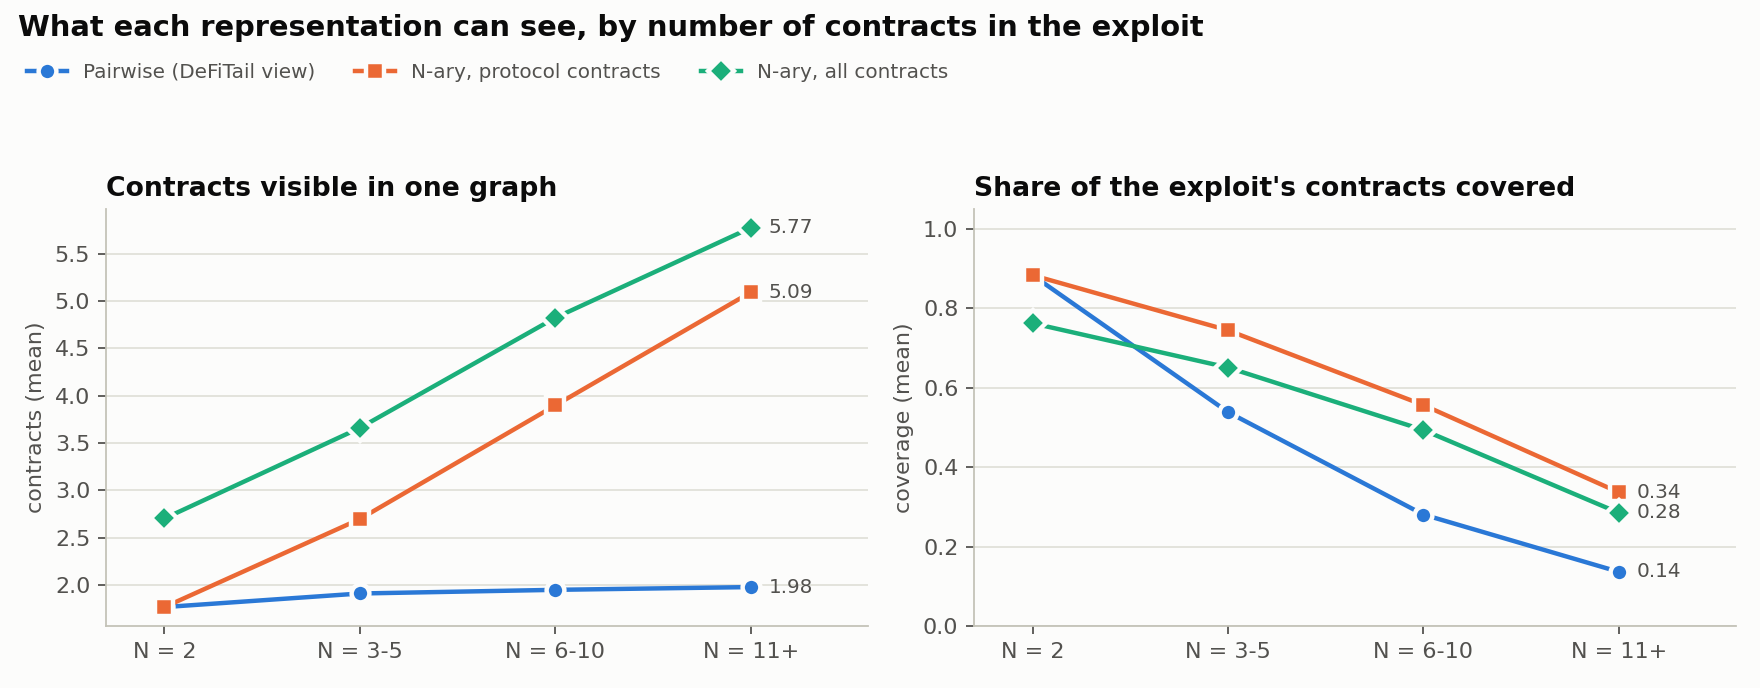

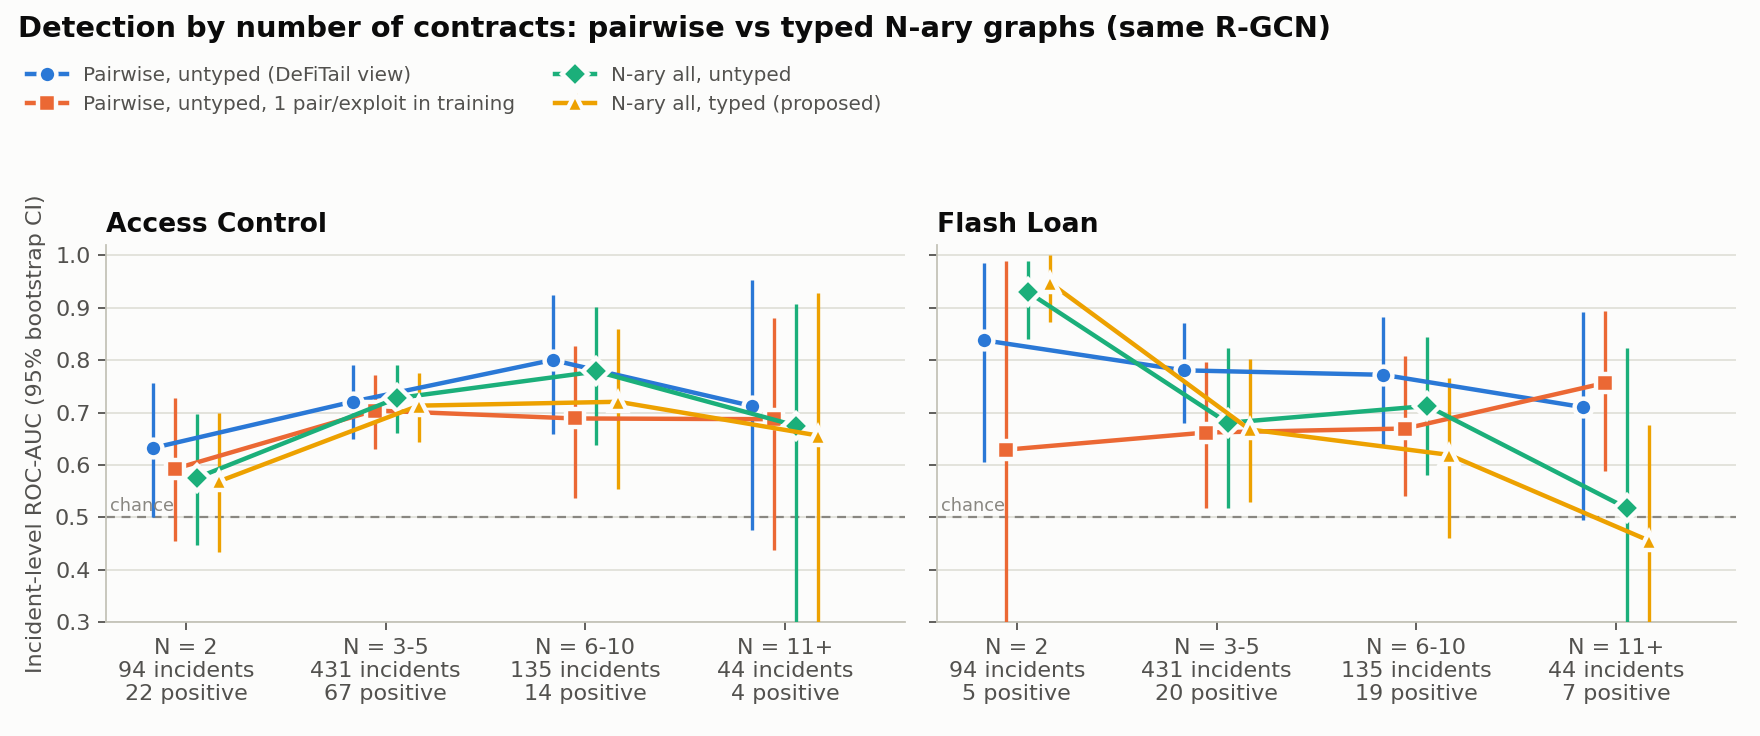

,test,task,a,b,subset,diff,ci_lo,ci_hi
0,N=2 minus N>=3,access_control,pairwise_untyped,NaN,all,-0.107,-0.254,0.030
1,N=2 minus N>=3,access_control,pairwise_typed,NaN,all,-0.100,-0.247,0.046
2,N=2 minus N>=3,access_control,nary_protocol_untyped,NaN,all,-0.215,-0.363,-0.077
3,N=2 minus N>=3,access_control,nary_protocol_typed,NaN,all,-0.161,-0.309,-0.006
4,N=2 minus N>=3,access_control,nary_all_untyped,NaN,all,-0.162,-0.307,-0.022
5,N=2 minus N>=3,access_control,nary_all_typed,NaN,all,-0.151,-0.304,-0.000
6,N=2 minus N>=3,access_control,pairwise_untyped_1pair,NaN,all,-0.109,-0.256,0.046
7,paired AUC difference,access_control,nary_all_typed,pairwise_untyped,all,-0.020,-0.079,0.042
8,paired AUC difference,access_control,nary_all_typed,pairwise_untyped,N>=3,-0.020,-0.091,0.049
9,paired AUC difference,access_control,nary_all_typed,pairwise_typed,all,-0.004,-0.065,0.061


In [10]:
display(Image(RES / "representation_coverage.png")); display(Image(RES / "auc_by_bucket.png"))
te.round(3)